# BDA500 Project 1 Regression: Predicting Student Math Scores

**Team members:** _Lionael Surya, Margil Parekh, Chehoon Shin_
**Dataset:** _Students Performance in Exams (Kaggle, spscientist)_
**Due:** October 14, 2026, 11:59 PM ET

| Section | Contributor |
|---|---|
| 0–3 Setup, Problem Framing, Data Understanding, EDA | Lionael Surya |

## 0. Setup

**Question:** Which libraries, paths, target, identifiers, dates, leakage columns, and random settings are required?

In [1]:
# Contributor: Lionael Surya — Section 0 Setup
import warnings, json
# %pip install plotly seaborn joblib -q
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Column roles (justified in Section 2.2)
TARGET = "math score"
NUM_FEATURES = ["reading score", "writing score"]
CAT_FEATURES = ["gender", "race/ethnicity", "parental level of education",
                "lunch", "test preparation course"]
ID_COLS, DATE_COLS, LEAKAGE_COLS = [], [], []   # none exist in this dataset

print("Libraries loaded")

Libraries loaded


## 1. Problem Framing

**Question:** What continuous value will be predicted in supervised learning?

**Supervised question:** Given a student's reading and writing scores, their background, and whether they finished the test-prep course, what math score (0–100) will they get?

| Item | Definition |
|---|---|
| **Target (y)** | `math score`, continuous from 0 to 100 |
| **Features (X)** | `reading score`, `writing score` (numeric); `gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course` (categorical) |
| **Unit of analysis** | One student |
| **Data source** | [Students Performance in Exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams), Kaggle (spscientist), 1,000 students |
| **Intended users** | School counsellors and academic-support staff |

**Why it's useful.** Schools often test reading and writing before math, or on a separate day. If we can estimate the math score from those earlier results, a counsellor can flag the students likely to land under 50 and book them into tutoring before the math exam instead of after it. Test prep is also one of the few inputs a school actually controls, so knowing how much it's worth could feed straight into a decision about funding more prep seats.

**Risks and limitations.** We see four:
- Gender, race/ethnicity and lunch (a stand-in for household income) are sensitive. The model should only point extra help toward students; nobody should lose a placement because of a prediction.
- Test prep might not cause anything, since the students who sign up may just be more motivated.
- The early-warning idea assumes reading and writing results arrive before math. If all three tests happen at one sitting, the model still predicts well but it's much less useful.
- At 1,000 rows we fall short of the preferred 5,000–10,000. It's the full public release, so we didn't sample anything, but we don't know which school or year it came from and the results may not carry over elsewhere.

In [2]:
# Contributor: Lionael Surya — Section 1 target overview
df_raw = pd.read_csv("StudentsPerformance.csv")
print(f"Target: '{TARGET}'  |  n = {df_raw[TARGET].size}")
df_raw[TARGET].describe().round(2)

Target: 'math score'  |  n = 1000


count    1000.00
mean       66.09
std        15.16
min         0.00
25%        57.00
50%        66.00
75%        77.00
max       100.00
Name: math score, dtype: float64

## 2.1 Load and Inspect

**Question:** What are the head, shape, structure, data types, summary statistics, and missing-value counts?

In [3]:
# Contributor: Lionael Surya — Section 2.1 Load and Inspect
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [5]:
print("Data types:")
print(df.dtypes.to_string())
print("\nNumeric summary:")
display(df.describe().T.round(2))
print("Categorical summary:")
display(df.describe(include="object").T)

Data types:
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
math score,1000.0,66.09,15.16,0.0,57.00,66.0,77.0,100.0
reading score,1000.0,69.17,14.60,17.0,59.00,70.0,79.0,100.0
writing score,1000.0,68.05,15.20,10.0,57.75,69.0,79.0,100.0


Categorical summary:


,count,unique,top,freq
gender,1000,2,female,518
race/ethnicity,1000,5,group C,319
parental level of education,1000,6,some college,226
lunch,1000,2,standard,645
test preparation course,1000,2,none,642


In [6]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing

,missing_count,missing_pct
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


**Findings.** The data has 1,000 rows and 8 columns: five text categories and three integer scores between 0 and 100. Not a single value is missing, so there's nothing to impute, though we'll leave a `SimpleImputer` in the pipeline in case future data arrives with gaps.

Math averages 66.1, a few points under reading (69.2) and writing (68.1), and it's the only subject where someone scored 0. All three have a standard deviation close to 15.

## 2.2 Column Roles and Cleaning

**Question:** Which columns are numeric, categorical, identifiers, dates, target, or leakage, and how are duplicates/removals handled?

In [7]:
# Contributor: Lionael Surya — Section 2.2 Column Roles
roles = pd.DataFrame({"Column": df.columns, "Dtype": df.dtypes.astype(str).values})
roles["Role"] = roles.Column.map(lambda x: "Target" if x == TARGET else "Identifier" if x in ID_COLS
                                 else "Date" if x in DATE_COLS else "Leakage" if x in LEAKAGE_COLS
                                 else "Numeric" if x in NUM_FEATURES else "Categorical")
display(roles)

,Column,Dtype,Role
0,gender,object,Categorical
1,race/ethnicity,object,Categorical
2,parental level of education,object,Categorical
3,lunch,object,Categorical
4,test preparation course,object,Categorical
5,math score,int64,Target
6,reading score,int64,Numeric
7,writing score,int64,Numeric


In [8]:
for c in CAT_FEATURES:
    print(df[c].value_counts(), "\n")

gender
female    518
male      482
Name: count, dtype: int64 

race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64 

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64 

lunch
standard        645
free/reduced    355
Name: count, dtype: int64 

test preparation course
none         642
completed    358
Name: count, dtype: int64 



In [9]:
# Duplicates and leakage checks
print("Exact duplicate rows:", df.duplicated().sum())
before = len(df); df = df.drop_duplicates().copy()
removal_log = pd.DataFrame([{"Action": "Drop exact duplicates", "Count": before - len(df), "Reason": "Exact duplicate records"}])
display(removal_log)
print("Rows with identical features (X) but different target:",
      df.drop(columns=TARGET).duplicated().sum())
print("Identifier columns:", ID_COLS or "none")
print("Date columns:", DATE_COLS or "none")
print("Leakage columns:", LEAKAGE_COLS or "none")

# Out-of-range check (scores must be 0–100)
print("\nScores outside 0–100:",
      ((df[[TARGET] + NUM_FEATURES] < 0) | (df[[TARGET] + NUM_FEATURES] > 100)).sum().sum())

# Extreme low math scores (kept, examined as outliers)
df[df[TARGET] < 20]

Exact duplicate rows: 0


,Action,Count,Reason
0,Drop exact duplicates,0,Exact duplicate records


Rows with identical features (X) but different target: 4
Identifier columns: none
Date columns: none
Leakage columns: none

Scores outside 0–100: 0


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
787,female,group B,some college,standard,none,19,38,32
980,female,group B,high school,free/reduced,none,8,24,23


**Column roles.** `math score` is the target. The two numeric features are `reading score` and `writing score`, and the other five columns (`gender`, `race/ethnicity`, `parental level of education`, `lunch`, `test preparation course`) are categorical. There's no student ID and no date, which rules out time-based splits or grouping by student.

Leakage would only creep in if we built something like an average or total score, because that number already contains the math score; we don't create one. We treat reading and writing as fair predictors on the assumption that students sit those tests before math, or at least separately.

**Cleaning.** We didn't drop anything. There are no exact duplicate rows, and while four rows match another student on every feature, they have a different math score, which just means two real students share a profile. Every score falls inside 0–100.

The very low scorers look genuine. The student with a 0 in math also scored 17 in reading and 10 in writing, and a typo wouldn't hit all three subjects at once, so we keep them and check how they affect the residuals in Section 6.5.

**Encoding plan for Section 5:** one-hot for every categorical column. Parental education does have an order, but the steps between levels aren't equal and it isn't obvious whether "some college" belongs above or below an associate's degree, so an ordinal code would force a spacing we can't defend.

## 3.1 Histograms and Boxplots

**Question:** What do important numeric distributions and boxplots reveal about spread, skewness, and outliers?

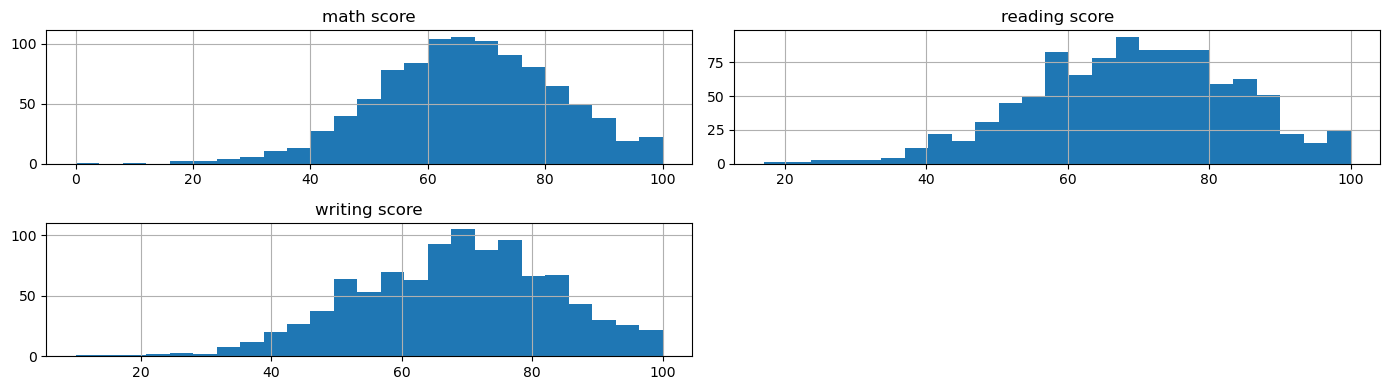

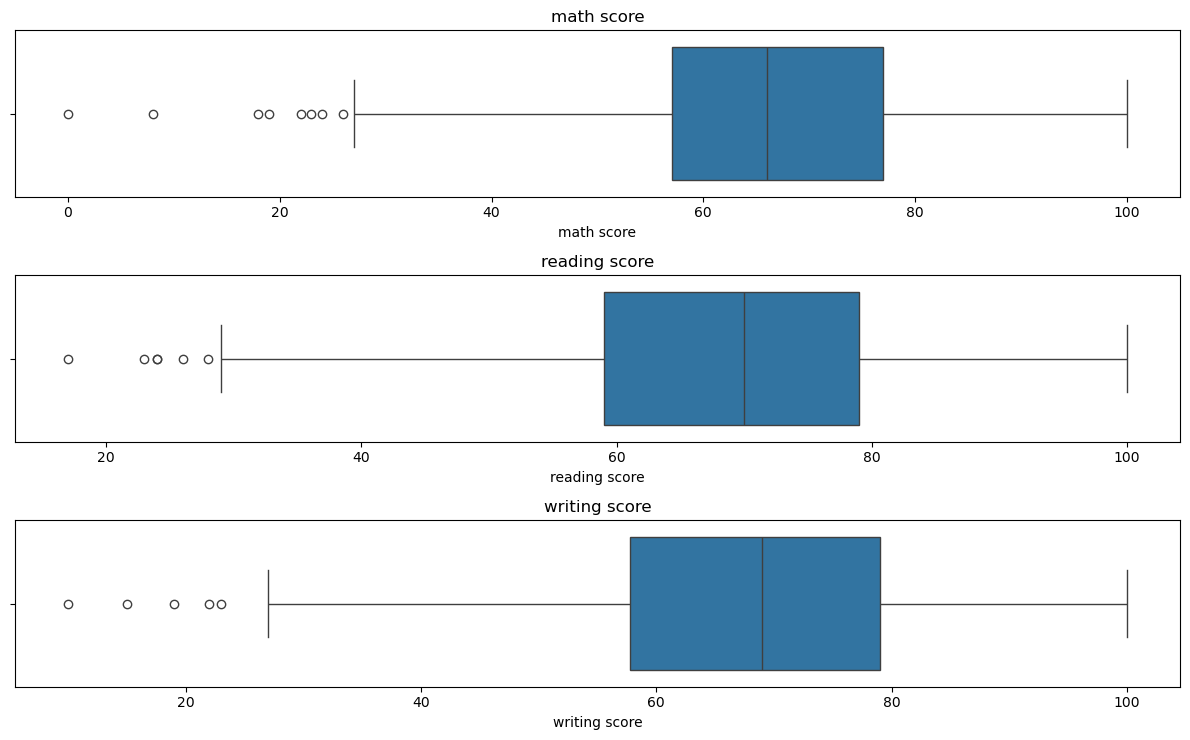

In [10]:
# Contributor: Lionael Surya — Section 3.1 Distributions
scores = [TARGET] + NUM_FEATURES
df[scores].hist(figsize=(14, 4), bins=25); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(len(scores), 1, figsize=(12, 2.5 * len(scores)))
for ax, col in zip(axes, scores): sns.boxplot(x=df[col], ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

In [11]:
# Mean vs median (skew) and outliers beyond mean ± 3 standard deviations
rows = []
for col in scores:
    mean_s, std_s = df[col].mean(), df[col].std()
    lower_bound, upper_bound = mean_s - 3 * std_s, mean_s + 3 * std_s
    out_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
    rows.append({"column": col, "mean": round(mean_s, 1), "median": df[col].median(),
                 "lower_bound": round(lower_bound, 1), "upper_bound": round(upper_bound, 1),
                 "n_outliers": out_mask.sum(), "outlier_values": sorted(df.loc[out_mask, col].values),
                 "n_at_100": (df[col] == 100).sum()})
pd.DataFrame(rows)

,column,mean,median,lower_bound,upper_bound,n_outliers,outlier_values,n_at_100
0,math score,66.1,66.0,20.6,111.6,4,"[0, 8, 18, 19]",7
1,reading score,69.2,70.0,25.4,113.0,4,"[17, 23, 24, 24]",17
2,writing score,68.1,69.0,22.5,113.6,4,"[10, 15, 19, 22]",14


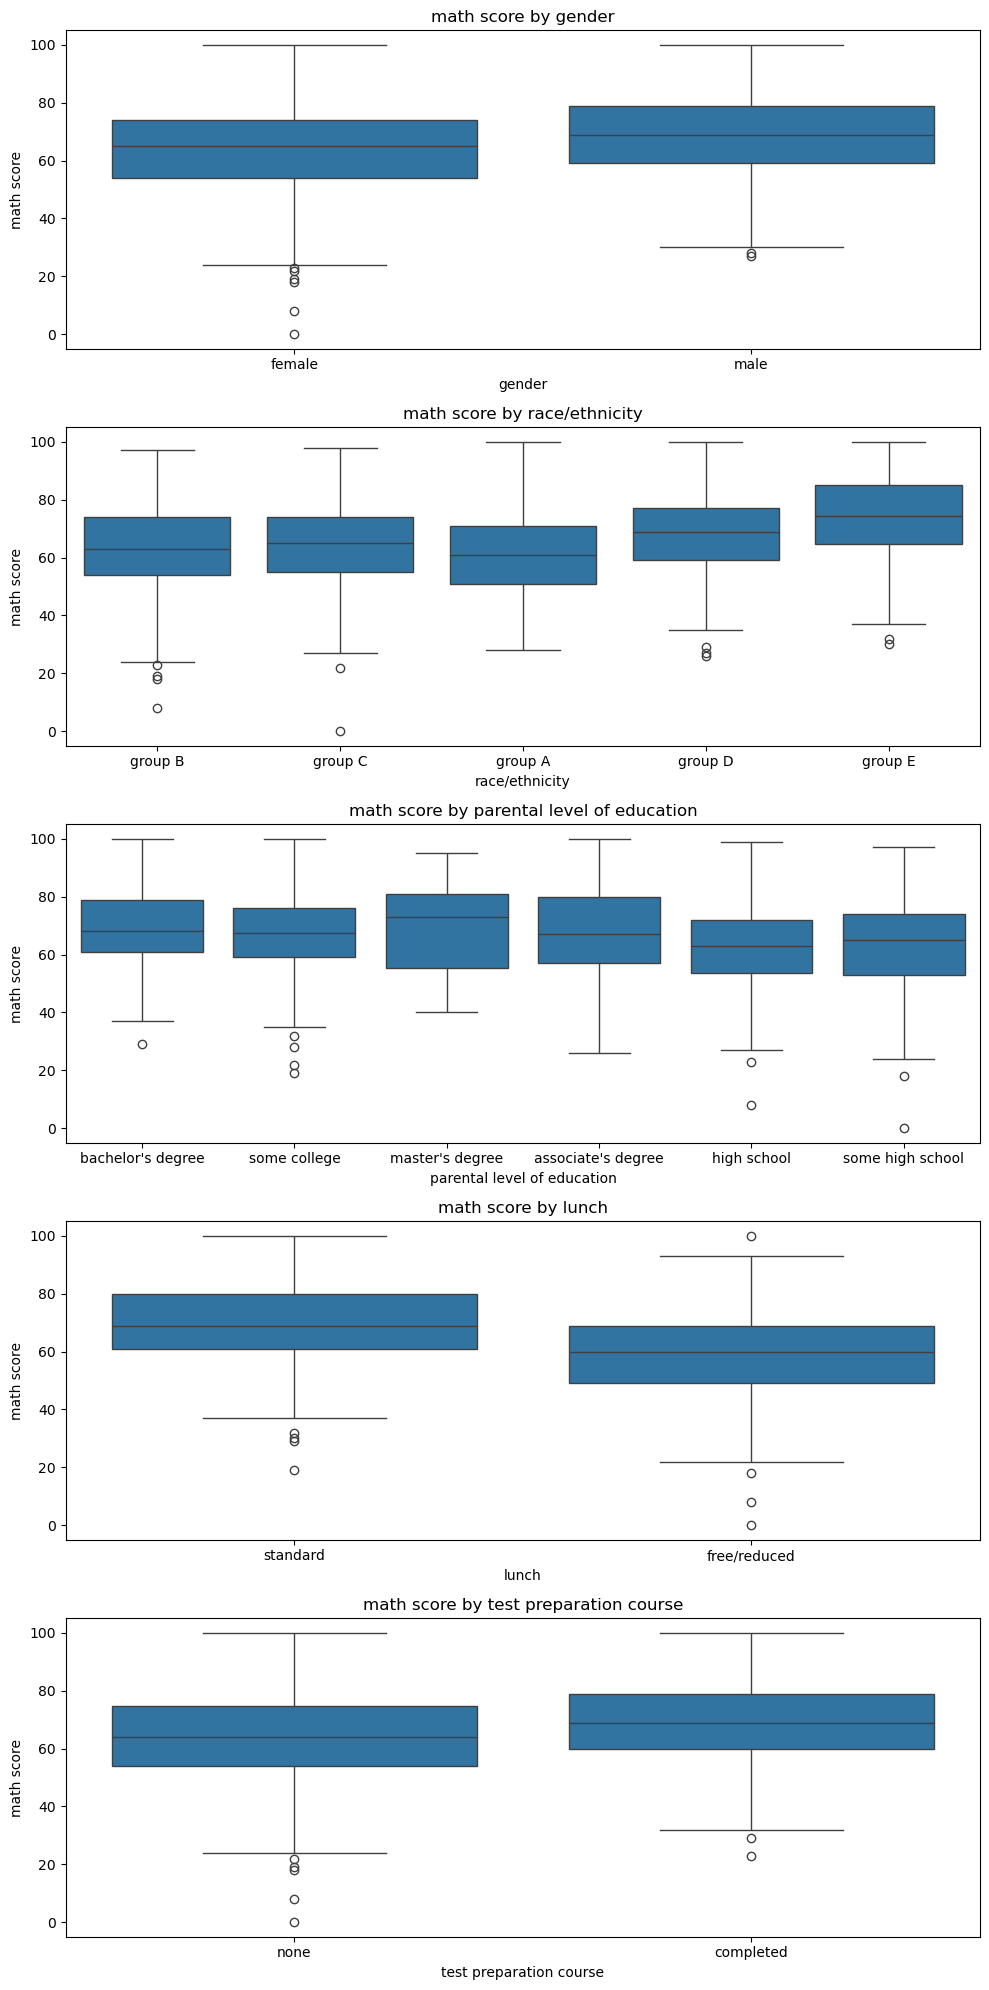

In [12]:
# Target distribution across each categorical feature
fig, axes = plt.subplots(len(CAT_FEATURES), 1, figsize=(10, 4 * len(CAT_FEATURES)))
for ax, col in zip(axes, CAT_FEATURES):
    sns.boxplot(data=df, x=col, y=TARGET, ax=ax)
    ax.set_title(f"{TARGET} by {col}")
plt.tight_layout(); plt.show()

**Findings.** All three scores lean slightly left: the mean sits just under the median (math 66.1 vs 66, reading 69.2 vs 70, writing 68.1 vs 69) because a small tail of very weak students pulls it down. That's too mild to justify transforming the target.

We flagged outliers with the mean ± 3 standard deviations rule from Lab 1. Each subject has exactly 4, all on the low side: math 0, 8, 18 and 19; reading 17 to 24; writing 10 to 22. Nothing is unusually high, since every upper bound sits above 111, past the top of the scale, although 7 students hit the 100 ceiling in math against 17 in reading. The three scores share a similar spread (standard deviation near 15), and we standardise them in Section 5 anyway because Ridge needs it.

By category, standard-lunch students average about 11 points more in math than free/reduced-lunch students, group E sits 12 above group A, finishing test prep adds 5.6 and males score 5.1 higher. Parental education is the odd one out. Its pattern is weak and not quite in order, with "high school" (62.1) at the bottom instead of "some high school" (63.5).

## 3.2 Correlations and Target Relationships

**Question:** Which numeric variables correlate, and how do at least two important predictors relate to the target?

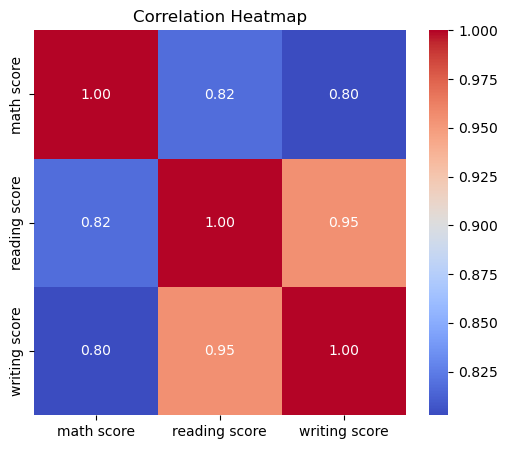

In [13]:
# Contributor: Lionael Surya — Section 3.2 Correlations
corr = df[scores].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap"); plt.show()

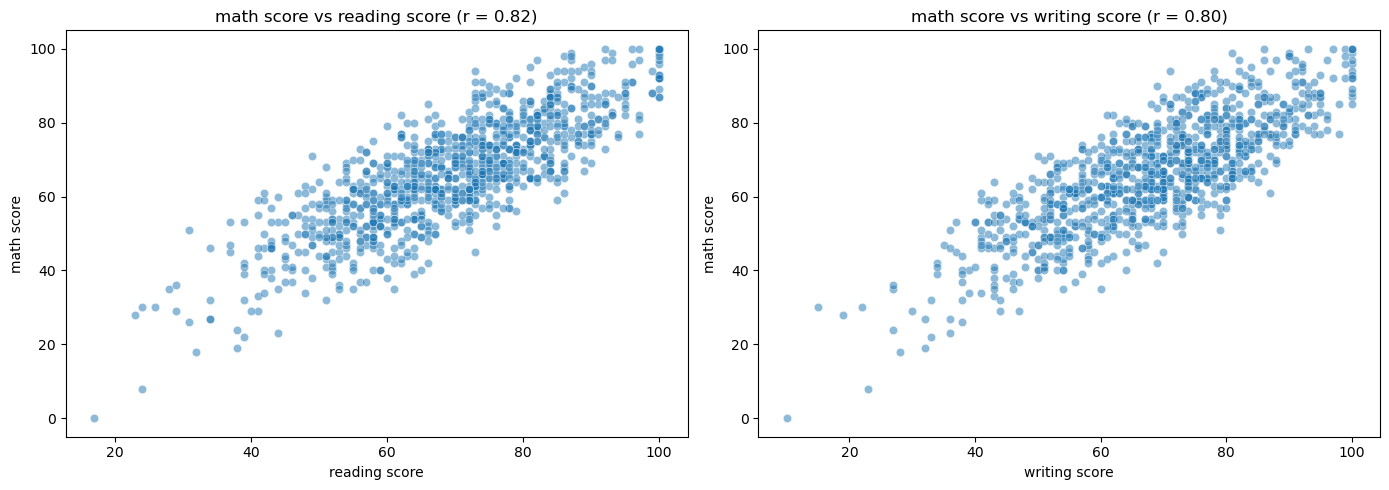

In [14]:
# Predictor vs target: reading and writing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, NUM_FEATURES):
    sns.scatterplot(data=df, x=col, y=TARGET, alpha=0.5, ax=ax)
    ax.set_title(f"{TARGET} vs {col} (r = {df[col].corr(df[TARGET]):.2f})")
plt.tight_layout(); plt.show()

,feature,max_gap_points
1,race/ethnicity,12.2
3,lunch,11.1
2,parental level of education,7.6
4,test preparation course,5.6
0,gender,5.1


lunch         test preparation course
free/reduced  completed                  63.0
              none                       56.5
standard      completed                  73.5
              none                       68.1
Name: math score, dtype: float64

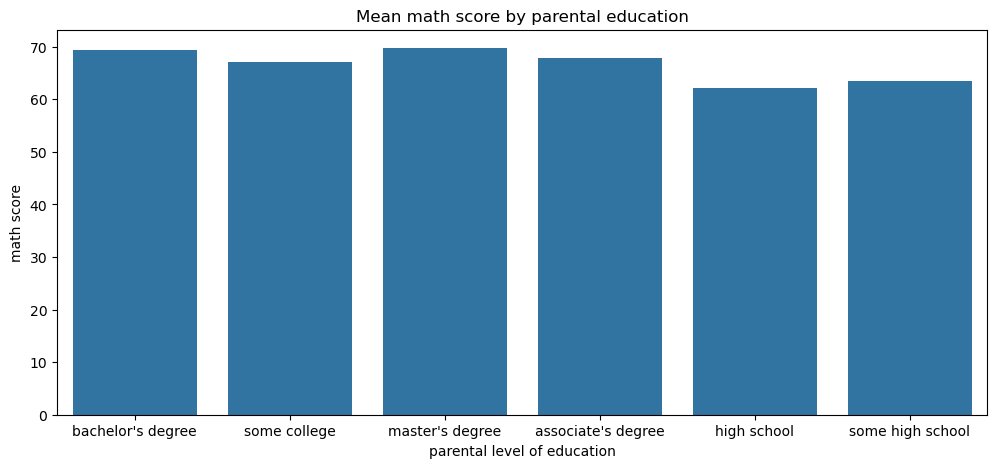

parental level of education
high school           62.1
some high school      63.5
some college          67.1
associate's degree    67.9
bachelor's degree     69.4
master's degree       69.7
Name: math score, dtype: float64

In [15]:
# Mean math score and gap (best level minus worst level) per category
rows = []
for col in CAT_FEATURES:
    means = df.groupby(col)[TARGET].mean()
    rows.append({"feature": col, "max_gap_points": round(means.max() - means.min(), 1)})
display(pd.DataFrame(rows).sort_values("max_gap_points", ascending=False))

# Lunch and test prep together
display(df.groupby(["lunch", "test preparation course"])[TARGET].mean().round(1))

plt.figure(figsize=(12, 5))
sns.barplot(data=df, x="parental level of education", y=TARGET, errorbar=None)
plt.title("Mean math score by parental education"); plt.show()
display(df.groupby("parental level of education")[TARGET].mean().round(1).sort_values())

**Findings.** Reading (r = 0.82) and writing (r = 0.80) both track math closely, and the scatterplots show a straight-line trend with fairly even spread, which suits Linear and Ridge regression.

The catch? Reading and writing correlate with each other at 0.95, so they're close to redundant. Plain linear regression can split the credit between them in unstable ways, and Ridge's L2 penalty exists for exactly this situation; it's the main reason Ridge belongs in the Section 6 comparison.

Ranked by the gap in mean math score between their best and worst level, the categories go race/ethnicity (12.2 points), lunch (11.1), parental education (7.6), test prep (5.6) and gender (5.1). Lunch and test prep stack on top of each other: standard lunch plus finished prep averages 73.5, while free/reduced lunch with no prep averages 56.5.

## 3.3 Possible Cluster Structure

**Question:** Does a scatterplot of two important features reveal possible grouping, overlap, or outliers?

        math score  reading score  writing score
gender                                          
female        63.6           72.6           72.5
male          68.7           65.5           63.3


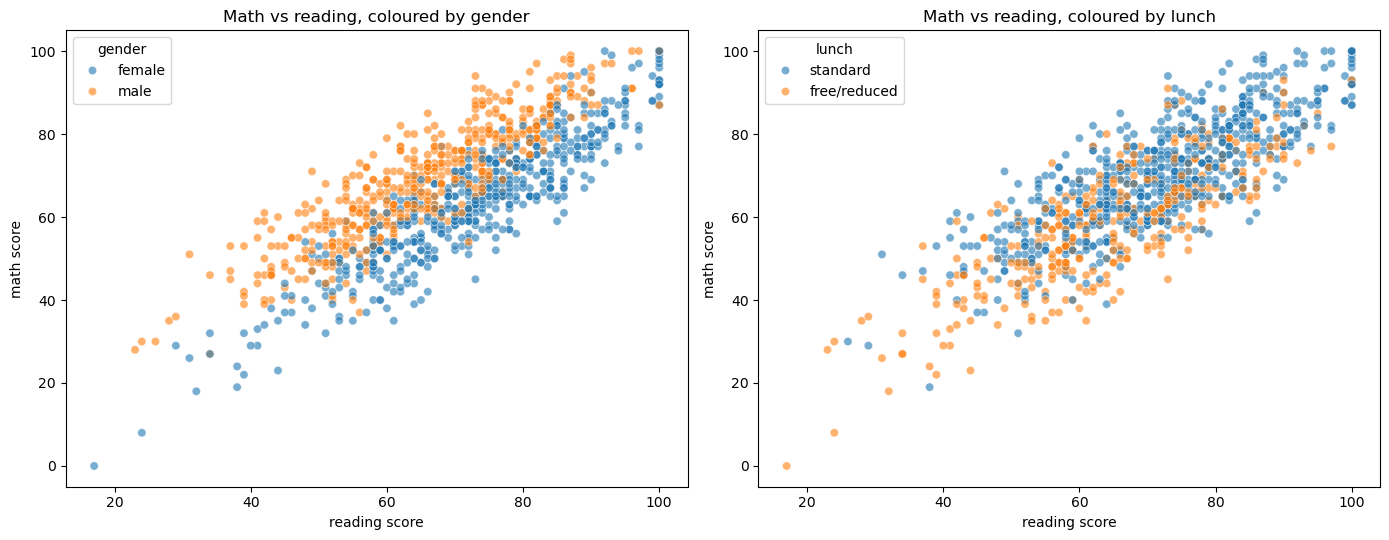

reading score  gender
(0, 50]        female    33.4
               male      49.2
(50, 70]       female    53.7
               male      63.8
(70, 85]       female    68.0
               male      79.6
(85, 100]      female    82.6
               male      92.9
Name: math score, dtype: float64

In [16]:
# Contributor: Lionael Surya — Section 3.3 Grouping
print(df.groupby("gender")[scores].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df, x="reading score", y=TARGET, hue="gender", alpha=0.6, ax=axes[0])
axes[0].set_title("Math vs reading, coloured by gender")
sns.scatterplot(data=df, x="reading score", y=TARGET, hue="lunch", alpha=0.6, ax=axes[1])
axes[1].set_title("Math vs reading, coloured by lunch")
plt.tight_layout(); plt.show()

# Gender gap in math at similar reading scores
reading_band = pd.cut(df["reading score"], bins=[0, 50, 70, 85, 100])
df.groupby([reading_band, "gender"])[TARGET].mean().round(1)

**Findings.** Gender splits the scatter into two bands. Females score higher in reading (72.6 vs 65.5) and writing (72.5 vs 63.3) but lower in math (63.6 vs 68.7), so at any given reading score a male student tends to score well above a female student in math. The table under the plots puts numbers on it: among students reading 50 or below, males average 15.8 points more in math, and in every higher reading band the gap sits between 10 and 12 points. The gap is widest among the weakest readers, which hints at a gender × reading interaction, though only the lowest band stands out. It also explains why gender looks weak on its own (a 5-point gap) yet carries real information once reading is in the model, so it stays.

Lunch doesn't separate anything; free/reduced-lunch students drift toward the lower left but show up across the whole range.

We don't see natural clusters. The students form one long cloud along the reading–math diagonal, and the four who scored under 20 in math sit at its bottom-left end, low in every subject, following the trend instead of breaking it. Expect them to produce some of the largest residuals anyway.

### Summary for modelling (handoff to Sections 5–6)
| Decision | Choice | Reason |
|---|---|---|
| Missing values | None present; optional `SimpleImputer` safeguard | 0 missing in all columns |
| Rows removed | None | 0 duplicates; outliers are genuine |
| Numeric preprocessing | Median `SimpleImputer` → `StandardScaler` on reading, writing | Ridge needs it; puts features on a common scale |
| Categorical encoding | Most-frequent `SimpleImputer` → `OneHotEncoder(handle_unknown="ignore")` on all 5 | Nominal categories; parental-education gaps aren't equal |
| Key risk | Reading–writing collinearity (r = 0.95) | Favours Ridge; read linear coefficients with care |

## 5. Preprocessing

**Question:** How are missing values, categorical encoding, and numeric scaling performed ?

In [17]:
# Contributor: Lionael Surya — Section 5 Preprocessing
df_model = df.drop(columns=ID_COLS + DATE_COLS + LEAKAGE_COLS, errors="ignore").copy()
X = df_model.drop(columns=TARGET)
y = df_model[TARGET]

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer([("num", num_pipe, num_features), ("cat", cat_pipe, cat_features)])

print("Numeric features:", num_features)
print("Categorical features:", cat_features)
print("Columns after encoding:", len(num_features) + sum(len(X[c].unique()) for c in cat_features))

Numeric features: ['reading score', 'writing score']
Categorical features: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
Columns after encoding: 19


**Answer.** Both pipelines sit inside one `ColumnTransformer`, and every model refits it on each training fold, so test rows never touch the imputer, scaler or encoder.

- **Missing values:** median for the two scores and the most frequent level for the categories. The data has no gaps, so these only matter if future students arrive with blanks.
- **Encoding:** one-hot for all five categorical columns (17 dummy columns); `handle_unknown="ignore"` turns a level the model never saw into all zeros instead of an error.
- **Scaling:** `StandardScaler` on reading and writing, because Ridge's penalty assumes every coefficient is on the same scale.

That gives 19 columns going into each model.

## 6.1 Regression Configuration Counts

**Question:** How many configurations result from test sizes 10%, 25%, 30%; random states 0 and 42; five-fold CV; alpha 1; and polynomial degrees  3?

In [18]:
# Contributor: Lionael Surya — Section 6.1 Configuration Counts
test_sizes = [0.10, 0.25, 0.30]; random_states = [0, 42]; cv_folds = 5; alpha = 1.0; degrees = [3]

# 3 test sizes x 2 random states x 1 CV setting x 1 fixed hyperparameter (alpha or degree)
per_model = len(test_sizes) * len(random_states) * 1
counts = {"Linear Regression": per_model,
          "Ridge Regression": per_model * 1,
          "Polynomial Regression": per_model * len(degrees)}
display(pd.Series(counts, name="Configurations").to_frame())
print("Total configurations:", sum(counts.values()))

,Configurations
Linear Regression,6
Ridge Regression,6
Polynomial Regression,6


Total configurations: 18


## 6.2 Cross-Validated Regression Results

**Question:** What are mean and standard deviation of CV MAE, RMSE, and R-squared for every required configuration?

In [19]:
# Contributor: Chaehoon Shin - Section 6.2 Validate Regression Results
def regression_pipeline(model_name, degree=None, alpha=None):
    steps = [("preprocessor", preprocessor)]
    if model_name == "Linear Regression":
        steps.append(("regressor", LinearRegression()))
    elif model_name == "Ridge Regression":
        steps.append(("regressor", Ridge(alpha=alpha)))
    elif model_name == "Polynomial Regression":
        steps.append(("poly", PolynomialFeatures(degree=degree, include_bias=False)))
        steps.append(("regressor", LinearRegression()))
    return Pipeline(steps)

# (model name, degree, alpha) for every model we compare
model_specs = ([("Linear Regression", None, None), ("Ridge Regression", None, alpha)]
               + [("Polynomial Regression", d, None) for d in degrees])
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
records = []

for ts in test_sizes:
    for rs in random_states:
        # Hold out the test set; 5-fold CV runs on the training part only
        Xtr, Xhold, ytr, yhold = train_test_split(X, y, test_size=ts, random_state=rs)
        cv = KFold(n_splits=cv_folds, shuffle=True, random_state=rs)
        for name, d, a in model_specs:
            s = cross_validate(regression_pipeline(name, d, a), Xtr, ytr, cv=cv, scoring=scoring)
            records.append({
                "Model": name,
                "Feature_Set": str(X.columns.tolist()),
                "CV_or_Split": f"{cv_folds}-fold; test={ts}; state={rs}",
                "Best_Params": str({"degree": d, "alpha": a}),
                "MAE": -s["test_MAE"].mean(), "MAE_SD": s["test_MAE"].std(),    # negative scores -> positive
                "RMSE": -s["test_RMSE"].mean(), "RMSE_SD": s["test_RMSE"].std(),
                "R2": s["test_R2"].mean(), "R2_SD": s["test_R2"].std(),
                "Test_Size": ts, "Random_State": rs, "Degree": d, "Alpha": a,
                "Notes": "Training-fold metrics only"})

# Compile and export results
regression_results = pd.DataFrame(records)
reg_export = regression_results[["Model", "Feature_Set", "CV_or_Split", "Best_Params", "MAE", "RMSE", "R2", "Notes"]]
OUTPUT_DIR = Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
with pd.ExcelWriter(OUTPUT_DIR / "BDA500_Project1_Results.xlsx", engine="openpyxl") as w:
    reg_export.to_excel(w, sheet_name="Regression_Results", index=False)
print("Exports saved")

display(regression_results.drop(columns=["Feature_Set", "CV_or_Split", "Best_Params", "Notes"])
        .sort_values(["Model", "Test_Size", "Random_State"]).round(3))
display(regression_results.groupby("Model").size().to_frame("Rows"))

Exports saved


,Model,MAE,MAE_SD,RMSE,RMSE_SD,R2,R2_SD,Test_Size,Random_State,Degree,Alpha
0,Linear Regression,4.279000e+00,2.360000e-01,5.349000e+00,2.630000e-01,8.760000e-01,7.000000e-03,0.10,0,NaN,NaN
3,Linear Regression,4.339000e+00,2.390000e-01,5.421000e+00,2.580000e-01,8.640000e-01,2.000000e-02,0.10,42,NaN,NaN
6,Linear Regression,4.307000e+00,2.530000e-01,5.371000e+00,3.340000e-01,8.740000e-01,1.900000e-02,0.25,0,NaN,NaN
9,Linear Regression,4.314000e+00,1.140000e-01,5.391000e+00,1.640000e-01,8.690000e-01,9.000000e-03,0.25,42,NaN,NaN
12,Linear Regression,4.356000e+00,4.310000e-01,5.407000e+00,4.530000e-01,8.760000e-01,2.500000e-02,0.30,0,NaN,NaN
15,Linear Regression,4.349000e+00,2.050000e-01,5.412000e+00,1.870000e-01,8.660000e-01,1.200000e-02,0.30,42,NaN,NaN
2,Polynomial Regression,1.574088e+10,1.659176e+10,9.510341e+10,8.222688e+10,-6.563710e+19,6.502550e+19,0.10,0,3.0,NaN
5,Polynomial Regression,1.758345e+10,1.517282e+10,1.625715e+11,1.630421e+11,-2.458149e+20,3.946087e+20,0.10,42,3.0,NaN
8,Polynomial Regression,4.112816e+10,1.835812e+10,2.400302e+11,1.155485e+11,-3.213340e+20,2.957184e+20,0.25,0,3.0,NaN
11,Polynomial Regression,7.859918e+10,4.554730e+10,5.558377e+11,4.197380e+11,-2.175894e+21,2.196942e+21,0.25,42,3.0,NaN


,Rows
Model,
Linear Regression,6
Polynomial Regression,6
Ridge Regression,6


## 6.3 Regression Comparison and Selection

**Question:** Which model wins primarily on cross-validated RMSE while considering MAE, R-squared, variability, simplicity, and interpretability?

,MAE,RMSE,RMSE_SD,R2
Model,,,,
Ridge Regression,4.320000e+00,5.389000e+00,2.780000e-01,8.710000e-01
Linear Regression,4.324000e+00,5.392000e+00,2.760000e-01,8.710000e-01
Polynomial Regression,5.309244e+10,3.397085e+11,2.251475e+11,-9.645690e+20


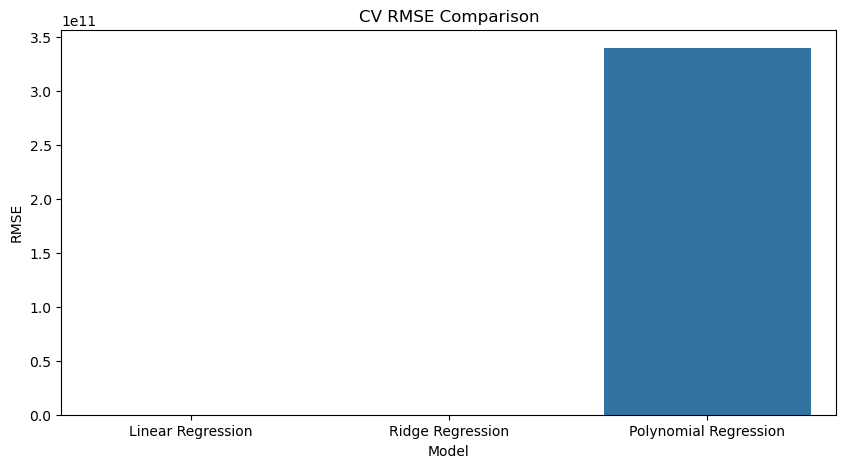

,Selected
Model,Ridge Regression
CV_or_Split,5-fold; test=0.1; state=0
Best_Params,"{'degree': None, 'alpha': 1.0}"
MAE,4.276509
MAE_SD,0.236872
RMSE,5.348225
RMSE_SD,0.263356
R2,0.875998
R2_SD,0.00685
Test_Size,0.1


In [20]:
# Contributor: Chaehoon Shin - Section 6.3 Comparison and Selection

# Comparison table: each model averaged over its 6 configurations
model_summary = regression_results.groupby("Model")[["MAE", "RMSE", "RMSE_SD", "R2"]].mean().sort_values("RMSE")
display(model_summary.round(3))

plt.figure(figsize=(10, 5))
sns.barplot(data=regression_results, x="Model", y="RMSE", errorbar=None)
plt.title("CV RMSE Comparison"); plt.show()

# Select the configuration with the lowest CV RMSE
best_reg = regression_results.loc[regression_results.RMSE.idxmin()]
display(best_reg.drop("Feature_Set").to_frame("Selected"))

**Selection: Ridge Regression, 10% test set, random state 0.** It has the lowest CV RMSE of all 18 configurations (5.35), and it also has the lowest CV MAE (4.28) and the highest R² (0.876), so every metric points the same way.

Linear Regression is a near tie. Averaged over their six configurations, Ridge and Linear differ by 0.001 RMSE (5.389 vs 5.390), under 1% of the 0.28 fold-to-fold SD, and each Ridge configuration beats its Linear twin by about that sliver. With `alpha = 1` and 700–900 training rows, the penalty barely moves the coefficients.

Polynomial Regression fails badly. Degree 3 on all 19 encoded columns produces 1,539 features, more than the 560–720 rows each CV fold trains on, so plain least squares fits noise: CV RMSE ranges from 9.1 to 103.4, R² falls as low as −95, and the fold SD reaches 112. Section 3.3 pointed to one useful interaction (gender × reading), but it's buried among more than a thousand useless ones.

Ridge and Linear tie on simplicity and interpretability, since both keep one coefficient per input column, read as math-score points. Ridge gets the nod because it wins the primary criterion, and its L2 penalty keeps the reading and writing coefficients steady despite their 0.95 correlation.

## 6.4 Final Untouched Test Evaluation

**Question:** How does the selected model perform when its matching held-out test set is evaluated once?

In [21]:
# Contributor: Chaehoon Shin - Section 6.4 Test Evaluation
name = best_reg.Model; ts = float(best_reg.Test_Size); rs = int(best_reg.Random_State)
degree = None if pd.isna(best_reg.Degree) else int(best_reg.Degree)
alpha_sel = None if pd.isna(best_reg.Alpha) else float(best_reg.Alpha)

# Re-create the same split; the test set is used once, here
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=rs)
selected_regression = regression_pipeline(name, degree, alpha_sel).fit(X_train, y_train)
y_pred = selected_regression.predict(X_test)

final_metrics = pd.DataFrame([{"Model": name, "Test_Size": ts, "Random_State": rs,
                               "MAE": mean_absolute_error(y_test, y_pred),
                               "RMSE": mean_squared_error(y_test, y_pred) ** 0.5,
                               "R2": r2_score(y_test, y_pred)}])
display(final_metrics.round(3))

,Model,Test_Size,Random_State,MAE,RMSE,R2
0,Ridge Regression,0.1,0,4.589,5.816,0.836


Ridge scored MAE 4.59, RMSE 5.82 and R² 0.836 on the 100 untouched test students. That's 0.47 RMSE worse than its CV estimate of 5.35, and R² drops from 0.876. Part of the gap comes from the small test set, where one student off by 14 points moves RMSE noticeably; part is optimism from picking the best of 18 CV scores. A typical prediction still lands within about 5–6 points on the 0–100 scale.

## 6.5 Actual-vs-Predicted, Residuals, and Large Errors

**Question:** Where does the selected model perform well or poorly, and what explains large errors or outliers?

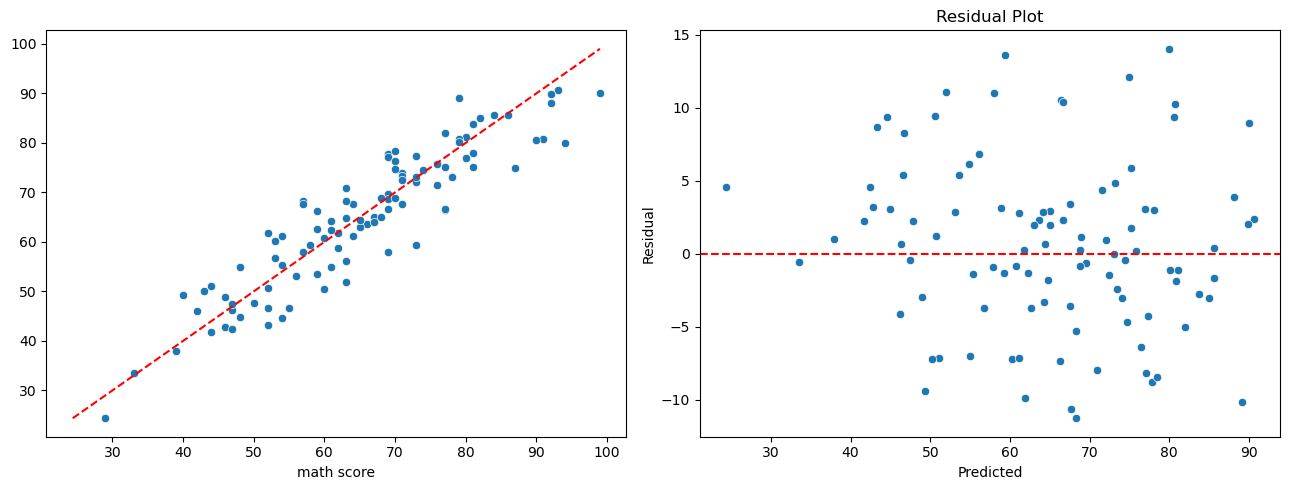

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score,Actual,Predicted,Absolute_Error
501,female,group B,associate's degree,standard,completed,87,92,94,79.958854,14.041146
279,male,group B,bachelor's degree,free/reduced,none,56,57,73,59.368721,13.631279
859,male,group C,associate's degree,free/reduced,none,73,72,87,74.905166,12.094834
918,female,group C,associate's degree,standard,completed,77,80,57,68.250338,11.250338
568,male,group B,high school,free/reduced,none,48,47,63,51.918281,11.081719
366,male,group C,high school,standard,completed,58,53,69,57.994352,11.005648
698,female,group D,associate's degree,standard,completed,78,79,57,67.596381,10.596381
553,male,group D,some college,free/reduced,none,62,64,77,66.442580,10.557420
693,female,group D,associate's degree,standard,none,77,73,77,66.622695,10.377305
784,male,group C,bachelor's degree,standard,completed,81,79,91,80.728332,10.271668


In [ ]:
# Contributor: TODO add name - Section 6.5 Residual Analysis
residuals = y_test.to_numpy() - y_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=y_test,y=y_pred,ax=axes[0]); lo=min(y_test.min(),y_pred.min()); hi=max(y_test.max(),y_pred.max()); axes[0].plot([lo,hi],[lo,hi],"r--"); axes[0].set(title="Residual Plot", xlabel="Predicted", ylabel="Residual")
sns.scatterplot(x=y_pred,y=residuals,ax=axes[1]); axes[1].axhline(0,color="red",ls="--"); axes[1].set(title="Residual Plot", xlabel="Predicted", ylabel="Residual")
plt.tight_layout(); plt.show()
errors=X_test.copy(); errors["Actual"] = y_test; errors["Predicted"]=y_pred; errors["Absolute_Error"]=np.abs(residuals)
display(errors.nlargest(10, "Absolute_Error"))

**Findings.** The model does well across the middle of the range. 63 of the 100 test students land within 5 points of their prediction, and the residuals scatter around zero (mean +0.5) with roughly the same spread from a predicted 45 up to 85, so a straight-line model isn't missing an obvious curve.

It's weaker at the top. The seven students who scored 90 or more were under-predicted by 7.3 points on average, and nobody got a prediction above 90.6; the model pulls strong students back toward the mean, and 8 of the 10 largest errors are under-predictions.

The 11 errors bigger than 10 points come from students whose math score doesn't follow their literacy scores. Row 279 scored 73 in math against 56 in reading, while rows 918 and 698 went the other way, about 20 points lower in math than in reading. None of the seven inputs can explain that kind of gap (math-specific tutoring, study habits or a bad test day might), so more data would shrink these errors more than a different model would.

The four students who scored under 20 in math (Section 2.2) all fell into the training set for this split. The lowest math score in the test set is 29, so they don't appear here.